 ## Modelo Escolhido: K-Means (Segmentação de Detratores)

A partir da nossa Análise Exploratória de Dados (EDA), identificamos que o público de detratores demanda uma atuação estratégica e personalizada, indo além da simples identificação das causas do atrito. Para viabilizar uma recuperação eficiente, é fundamental compreender a heterogeneidade desse grupo e priorizar as ações de acordo com o nível de impacto de cada cliente.

Diante disso, optamos pela aplicação do K-Means, um algoritmo de aprendizado não supervisionado que agrupa os clientes por padrões de similaridade comportamental e operacional. Essa abordagem permite criar segmentos bem delineados e estruturar planos de ação direcionados para cada perfil.

A seguir, apresentamos a metodologia de clusterização e a distribuição dos grupos identificados.

In [ ]:
# Importando as bibliotecas necessárias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
# Importando a base de dados
df = pd.read_csv("desafio_nps_fase_1.csv")
df.head()


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [ ]:
def classificador_nps(df):
    if df['nps_score']>=9:
        return 'Promotores'
    elif df['nps_score']>=7:
        return 'Neutro'
    else:
        return 'Detrator'

In [ ]:
df['clas_cliente'] = df.apply(classificador_nps, axis=1)

In [ ]:
prop_clientes = df['clas_cliente'].value_counts()/len(df)*100
prop_clientes

,count
clas_cliente,
Detrator,84.36
Neutro,11.24
Promotores,4.40


In [ ]:
## Relizando o arredondamento do NPS
df['nps_score_original'] = df['nps_score']
df['nps_score'] = df['nps_score'].round(0).astype(int)

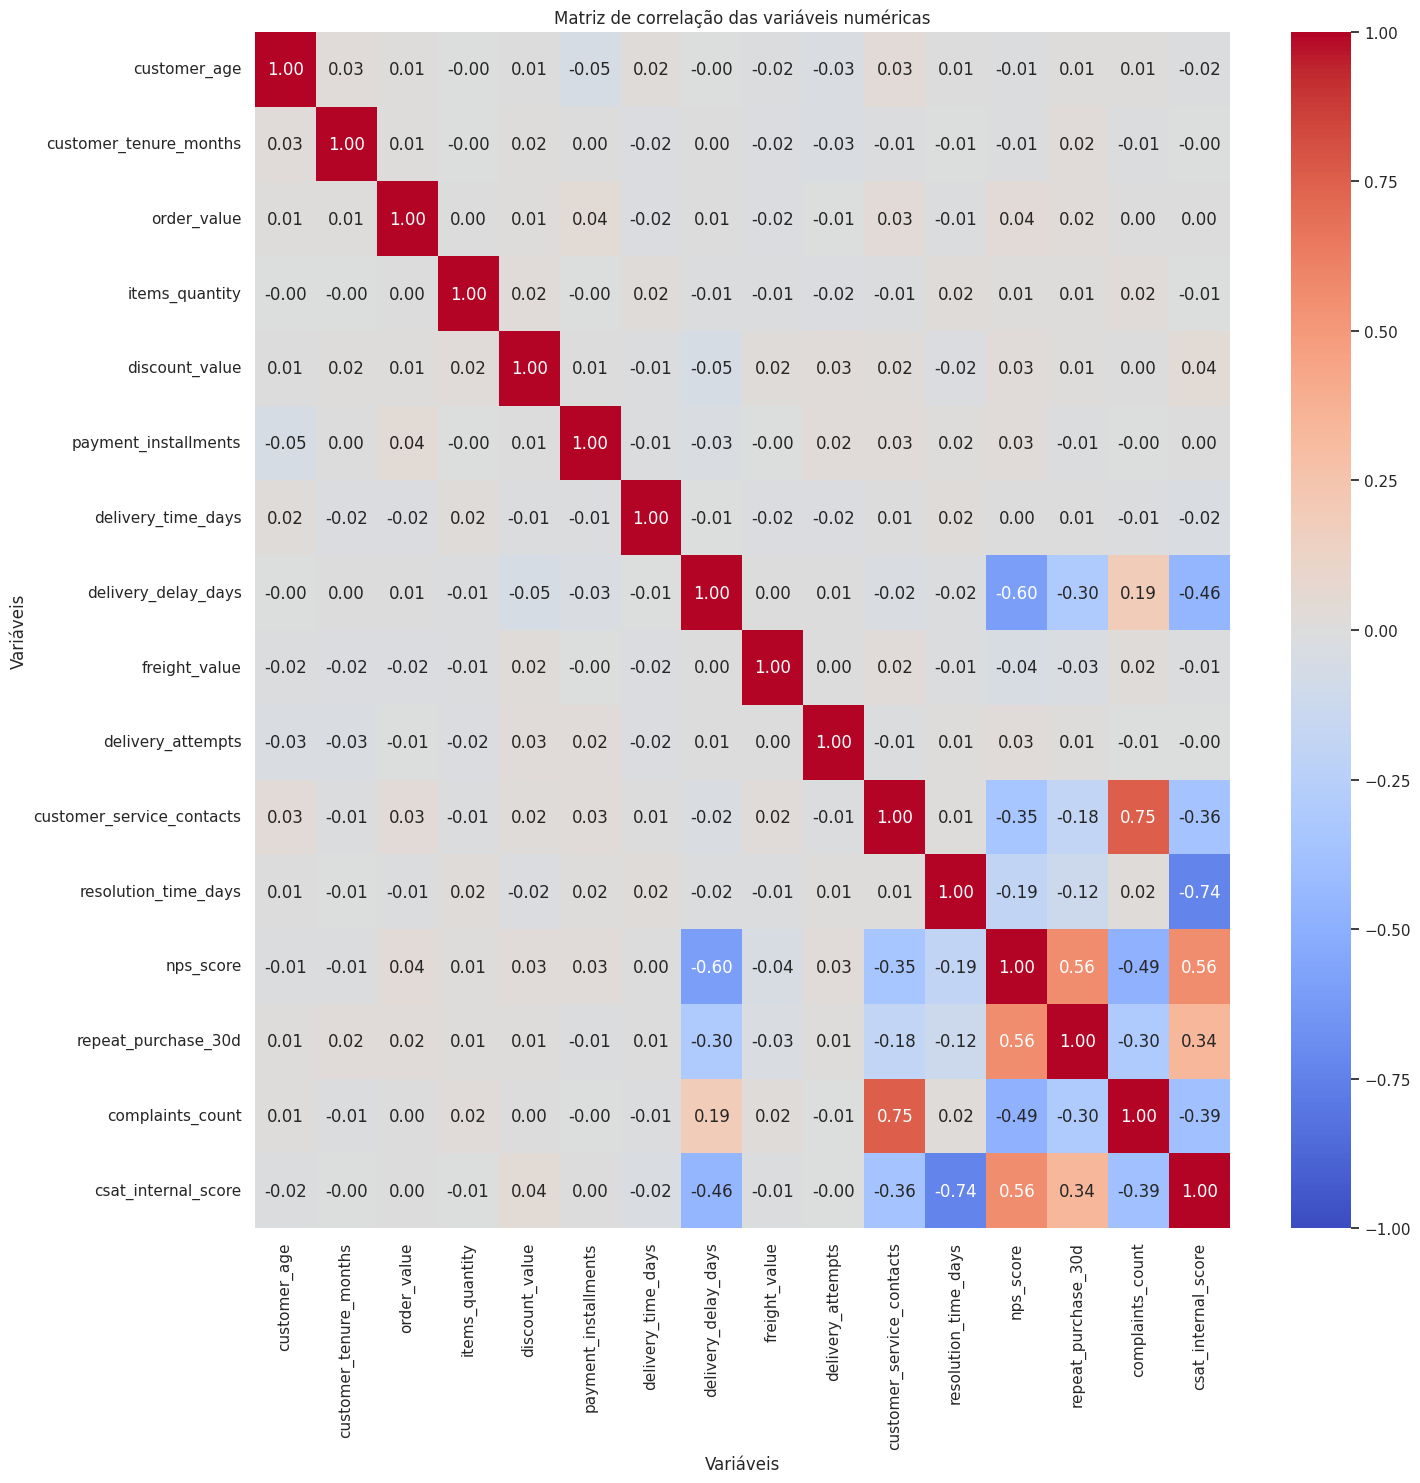

In [ ]:
## Verificando quais variaveis ficam relevantes com o NPS.
plt.figure(figsize=(15, 15))

sns.heatmap(
    df.drop(columns=['customer_id', 'order_id', 'nps_score_original']).corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlação das variáveis numéricas")
plt.xlabel("Variáveis")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()

## Para realizar a ideia do nosso modelo, focamos na grande massa da nossa base que sao os detratores.

Realizamos uma análise descritiva focada exclusivamente no segmento de detratores, considerando as variáveis que apresentaram correlação estatisticamente relevante com o NPS.

In [ ]:
detratores = df[df['nps_score'] <= 6.9].copy()
print(f"Total detratores: {len(detratores)}")

cols_interesse = [
    'delivery_delay_days', 'delivery_time_days', 'customer_service_contacts',
    'resolution_time_days', 'complaints_count', 'csat_internal_score',
    'order_value', 'freight_value', 'items_quantity', 'customer_age', 'customer_tenure_months'
]

print(detratores[cols_interesse].describe().round(2).to_string())

Total detratores: 2001
       delivery_delay_days  delivery_time_days  customer_service_contacts  resolution_time_days  complaints_count  csat_internal_score  order_value  freight_value  items_quantity  customer_age  customer_tenure_months
count              2001.00             2001.00                    2001.00               2001.00           2001.00              2001.00      2001.00        2001.00         2001.00        2001.0                 2001.00
mean                  2.47                8.01                       1.66                  5.73              4.52                 2.45       429.69          38.35            3.48          43.4                   61.67
std                   1.43                3.79                       1.25                  3.44              1.65                 2.14       288.23          12.06            1.68          14.8                   34.59
min                   0.00                2.00                       0.00                  0.00              

Realizamos a distribuição por cluster para quantificar os clientes em cada grupo e analisar as médias das variáveis por segmento.

In [ ]:
features_cluster = [
    'delivery_delay_days',
    'customer_service_contacts',
    'resolution_time_days',
    'complaints_count',
    'csat_internal_score'
]

scaler = StandardScaler()
X_det = scaler.fit_transform(detratores[features_cluster])

# Testar de 2 a 5 clusters
for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_det)
    # silhouette or print cluster sizes

km3 = KMeans(n_clusters=3, random_state=42, n_init=10)
detratores['cluster'] = km3.fit_predict(X_det)

print("Distribuição por cluster:")
print(detratores['cluster'].value_counts())

print("\nMédias por cluster:")
cluster_summary = detratores.groupby('cluster')[features_cluster + ['nps_score', 'order_value', 'repeat_purchase_30d']].mean().round(2)
print(cluster_summary.to_string())

Distribuição por cluster:
cluster
2    757
0    722
1    522
Name: count, dtype: int64

Médias por cluster:
         delivery_delay_days  customer_service_contacts  resolution_time_days  complaints_count  csat_internal_score  nps_score  order_value  repeat_purchase_30d
cluster                                                                                                                                                          
0                       2.18                       1.20                  2.58              3.91                 4.74       4.19       429.73                  0.0
1                       2.48                       3.21                  6.33              6.47                 1.08       2.50       450.14                  0.0
2                       2.74                       1.03                  8.34              3.75                 1.20       3.45       415.55                  0.0


#Realizamos a correlacao dos detratores com a NPS

In [ ]:
print("Correlações dentro dos detratores com nps_score:")
print(detratores[features_cluster + ['nps_score']].corr()['nps_score'].sort_values())

Correlações dentro dos detratores com nps_score:
delivery_delay_days         -0.509905
complaints_count            -0.330104
customer_service_contacts   -0.285841
resolution_time_days        -0.134541
csat_internal_score          0.446886
nps_score                    1.000000
Name: nps_score, dtype: float64


Foi realizada a separacao por grupo dos cluster

In [ ]:
features_cluster = [
    'delivery_delay_days',
    'customer_service_contacts',
    'resolution_time_days',
    'complaints_count',
    'csat_internal_score'
]

scaler = StandardScaler()
X_det = scaler.fit_transform(detratores[features_cluster])

km3 = KMeans(n_clusters=3, random_state=42, n_init=10)
detratores['cluster'] = km3.fit_predict(X_det)

cluster_names = {
    0: 'Grupo 1: Atrito Leve / Resolução Rápida (NPS Médio: 4.4)',
    1: 'Grupo 2: Suporte Lento / Gargalo Operacional (NPS Médio: 3.6)',
    2: 'Grupo 3: Críticos / Alto Atrito (NPS Médio: 2.5)'
}
detratores['Perfil'] = detratores['cluster'].map(cluster_names)

for var in ['resolution_time_days', 'complaints_count', 'csat_internal_score']:
    print(f"\n--- {var} ---")
    for g in [0, 1, 2]:
        sub = detratores[detratores['cluster'] == g][var]
        stats = sub.describe(percentiles=[0.25, 0.5, 0.75])
        stats_summary = {
            'min': round(stats['min'], 2),
            'q1': round(stats['25%'], 2),
            'median': round(stats['50%'], 2),
            'q3': round(stats['75%'], 2),
            'max': round(stats['max'], 2)
        }
        print(f"Grupo {g+1}: {stats_summary}")


--- resolution_time_days ---
Grupo 1: {'min': np.float64(0.0), 'q1': np.float64(1.0), 'median': np.float64(2.0), 'q3': np.float64(4.0), 'max': np.float64(8.0)}
Grupo 2: {'min': np.float64(0.0), 'q1': np.float64(4.0), 'median': np.float64(6.0), 'q3': np.float64(9.0), 'max': np.float64(11.0)}
Grupo 3: {'min': np.float64(0.0), 'q1': np.float64(7.0), 'median': np.float64(8.0), 'q3': np.float64(10.0), 'max': np.float64(11.0)}

--- complaints_count ---
Grupo 1: {'min': np.float64(0.0), 'q1': np.float64(3.0), 'median': np.float64(4.0), 'q3': np.float64(5.0), 'max': np.float64(8.0)}
Grupo 2: {'min': np.float64(4.0), 'q1': np.float64(6.0), 'median': np.float64(6.0), 'q3': np.float64(7.0), 'max': np.float64(11.0)}
Grupo 3: {'min': np.float64(0.0), 'q1': np.float64(3.0), 'median': np.float64(4.0), 'q3': np.float64(4.0), 'max': np.float64(7.0)}

--- csat_internal_score ---
Grupo 1: {'min': np.float64(1.7), 'q1': np.float64(3.7), 'median': np.float64(4.6), 'q3': np.float64(5.7), 'max': np.float64(

Relizando o modelo KMeans é um algoritmo de aprendizado não supervisionado, escolhemos ele para realizar a separacao dos nossos detratores.



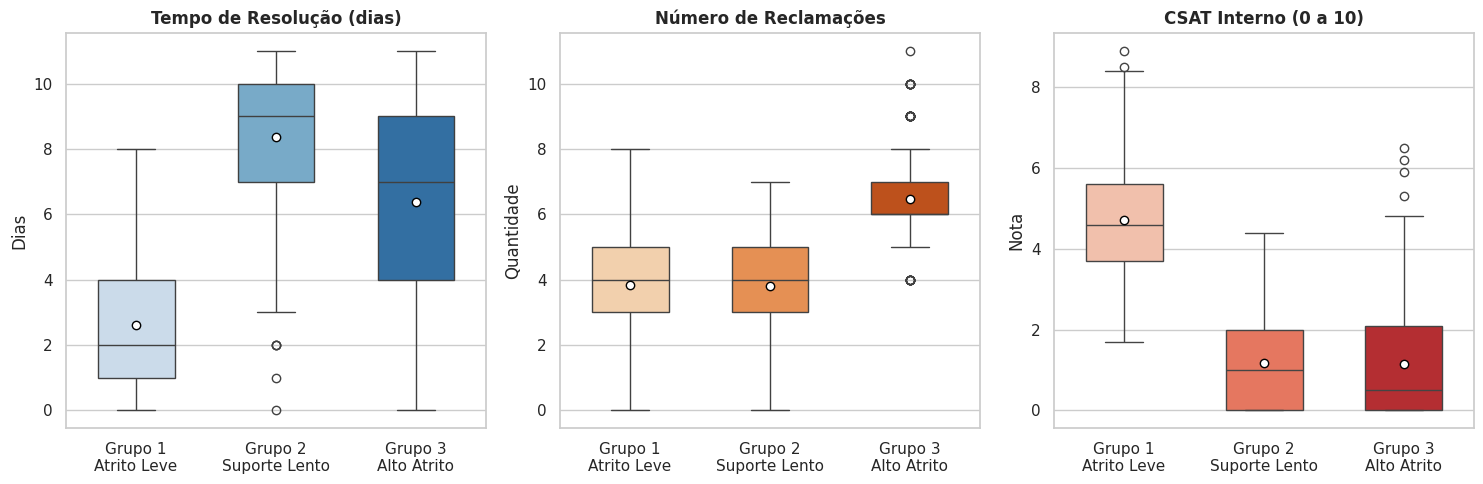

In [ ]:
detratores = df[df['nps_score'] <= 6.9].copy()

#Divisão em Treino (80%) e Teste (20%)
treino_det, teste_det = train_test_split(
    detratores, test_size=0.20, random_state=42
)

features_cluster = [
    'delivery_delay_days',
    'customer_service_contacts',
    'resolution_time_days',
    'complaints_count',
    'csat_internal_score',
]

#Pré-processamento e Treinamento do K-Means no Treino
scaler = StandardScaler()
X_train = scaler.fit_transform(treino_det[features_cluster])

km = KMeans(n_clusters=3, random_state=42, n_init=10)
treino_det['cluster'] = km.fit_predict(X_train)

#Projeção no conjunto de Teste (20%)
X_test = scaler.transform(teste_det[features_cluster])
teste_det['cluster'] = km.predict(X_test)

#Mapeamento dinâmico pelas médias (garante que os rótulos fiquem sempre certos)
medias = treino_det.groupby('cluster')[
    ['resolution_time_days', 'complaints_count', 'csat_internal_score']
].mean()

cluster_leve = medias['csat_internal_score'].idxmax()
outros = medias.drop(index=cluster_leve)
cluster_lento = outros['resolution_time_days'].idxmax()
cluster_alto = outros['complaints_count'].idxmax()

labels_map = {
    cluster_leve: 'Grupo 1\nAtrito Leve',
    cluster_lento: 'Grupo 2\nSuporte Lento',
    cluster_alto: 'Grupo 3\nAlto Atrito',
}

treino_det['perfil_nome'] = treino_det['cluster'].map(labels_map)
teste_det['perfil_nome'] = teste_det['cluster'].map(labels_map)

#Ordem fixa das colunas no gráfico
ordem_grupos = [
    'Grupo 1\nAtrito Leve',
    'Grupo 2\nSuporte Lento',
    'Grupo 3\nAlto Atrito',
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.set_theme(style='whitegrid')

# Gráfico 1: Tempo de Resolução
sns.boxplot(
    x='perfil_nome',
    y='resolution_time_days',
    hue='perfil_nome',
    legend=False,
    data=treino_det,
    order=ordem_grupos,
    ax=axes[0],
    palette='Blues',
    width=0.55,
    showmeans=True,
    meanprops={
        'marker': 'o',
        'markerfacecolor': 'white',
        'markeredgecolor': 'black',
        'markersize': '6',
    },
)
axes[0].set_title(
    'Tempo de Resolução (dias)', fontweight='bold', fontsize=12
)
axes[0].set_xlabel('')
axes[0].set_ylabel('Dias')

# Gráfico 2: Número de Reclamações
sns.boxplot(
    x='perfil_nome',
    y='complaints_count',
    hue='perfil_nome',
    legend=False,
    data=treino_det,
    order=ordem_grupos,
    ax=axes[1],
    palette='Oranges',
    width=0.55,
    showmeans=True,
    meanprops={
        'marker': 'o',
        'markerfacecolor': 'white',
        'markeredgecolor': 'black',
        'markersize': '6',
    },
)
axes[1].set_title(
    'Número de Reclamações', fontweight='bold', fontsize=12
)
axes[1].set_xlabel('')
axes[1].set_ylabel('Quantidade')

# Gráfico 3: CSAT Interno
sns.boxplot(
    x='perfil_nome',
    y='csat_internal_score',
    hue='perfil_nome',
    legend=False,
    data=treino_det,
    order=ordem_grupos,
    ax=axes[2],
    palette='Reds',
    width=0.55,
    showmeans=True,
    meanprops={
        'marker': 'o',
        'markerfacecolor': 'white',
        'markeredgecolor': 'black',
        'markersize': '6',
    },
)
axes[2].set_title(
    'CSAT Interno (0 a 10)', fontweight='bold', fontsize=12
)
axes[2].set_xlabel('')
axes[2].set_ylabel('Nota')

plt.tight_layout()
plt.show()

## Análise do Modelo e Planos de Ação

Analisando os grupos que foram criados temos :

Atrito leve : Sofreram atraso de entrega, mas o suporte respondeu rápido (tempo médio de resolução de 2,6 dias; mediana de 2 dias). Apresentam insatisfação moderada e são os mais fáceis de converter com ações de compensação.

Suporte lento : Abriram contatos parecido com o atrito leve, contudo o tempo de resolução foi excessivamente longo (média de 8,35 dias; mediana de 8 dias). O que destrói a confiança deste grupo é o SLA ineficiente do suporte técnico.

Alto Atrito : Tiveram atrito repetido e acumulado, com média de 3,2 contactos no SAC e 6,45 reclamações (mediana de 6 e valores até 11). Representam os clientes com maior risco de danos à reputação da marca.

## Proposta de Estrategia

Diante do cenário em que a grande maioria da base é composta por clientes insatisfeitos (84,36% de detratores), a abordagem de recuperação não deve ser genérica. A partir da modelagem não supervisionada (clusterização por K-Means), identificamos que os detratores possuem níveis de atrito distintos. Por isso, recomendamos uma estratégia segmentada em três frentes de ação prioritárias:

##Grupo 1 (Atrito leve)
**Ánalise:** Representa o grupo com maior probabilidade de conversão a curto prazo para a faixa de clientes neutros ou até promotores, exigindo menor esforço operacional.

**Oportunidade e acao:** Implementação de comunicação ativa pós-resolução confirmando se a solicitação foi atendida com excelência. Oferta de pedidos de desculpas institucionais acompanhados de incentivos brandos (como frete grátis na próxima compra ou cupom de desconto) para restabelecer a confiança antes da próxima pesquisa de NPS

##Grupo 2 (Suporte lento)
**Ánalise** : A causa da insatisfação está no tempo de fila e na falta de visibilidade do processo.

**Oportunidade e acao:** Revisão e encurtamento dos SLAs internos de atendimento para demandas logísticas e de pós-venda. Criação de régua de follow-up proativo e automatizado (via WhatsApp ou e-mail): informar preventivamente o cliente em que etapa está a resolução do seu chamado, alinhando expectativas e reduzindo a ansiedade da espera.

## Grupo 3 (Alto atrito)
**Ánalise** : Oportunidade Clientes em desgaste severo, com múltiplos contatos no SAC (média acima de 3 contatos) e o maior volume de reclamações registradas (média de 6,5 reclamações), apresentando as menores notas de NPS (média de 2,55) e alto risco de dano reputacional.

**Oportunidade e acao:** Evitar o churn definitivo e conter o impacto negativo em canais públicos (Reclame Aqui, Procon e redes sociais). Acompanhamento humanizado e dedicado com poder de alçada imediata (reembolso ágil, reenvio expresso ou substituição do produto sem atrito burocrático).